In [ ]:

import pandas as pd
import itertools
import matplotlib.pyplot as plt


In [ ]:
# Exercise 1: Propositional Logic

print("Truth Table: If it rains, then the road is wet")
print("P = It rains, Q = Road is wet\n")

print(f"{'P':<10}{'Q':<10}{'P -> Q':<10}")

for P, Q in itertools.product([True, False], repeat=2):
    implication = (not P) or Q
    print(f"{str(P):<10}{str(Q):<10}{str(implication):<10}")


Truth Table: If it rains, then the road is wet
P = It rains, Q = Road is wet

P         Q         P -> Q    
True      True      True      
True      False     False     
False     True      True      
False     False     True      


In [ ]:

# Exercise 2: First-Order Logic

def is_human(person):
    return person in humans

def is_mortal(person):
    # Rule: All humans are mortal
    if is_human(person):
        return True
    return False

# Facts
humans = {"Socrates"}

# Inference
person = "Socrates"

print("Fact 1: All humans are mortal.")
print("Fact 2: Socrates is a human.")

if is_mortal(person):
    print("Conclusion: Socrates is mortal.")
else:
    print("Conclusion: Socrates is not known to be mortal.")


Fact 1: All humans are mortal.
Fact 2: Socrates is a human.
Conclusion: Socrates is mortal.


In [ ]:

# Exercise 3: Probability of Events

data = {
    "Student": list(range(1, 11)),
    "Attendance": [
        "Attended", "Attended", "Attended", "Attended", "Attended",
        "Attended", "Absent", "Absent", "Absent", "Absent"
    ],
    "Result": [
        "Pass", "Pass", "Pass", "Pass", "Pass", "Fail",
        "Pass", "Fail", "Fail", "Fail"
    ]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df.to_string(index=False))

total = len(df)

# Event A: Student passed
A = df["Result"] == "Pass"

# Event B: Student attended
B = df["Attendance"] == "Attended"

P_A = A.sum() / total
P_B = B.sum() / total
P_A_and_B = (A & B).sum() / total
P_A_or_B = P_A + P_B - P_A_and_B

print("\nProbability Calculations:")
print(f"P(A) - Probability of passing: {P_A:.2f}")
print(f"P(B) - Probability of attendance: {P_B:.2f}")
print(f"P(A and B) - Passed and attended: {P_A_and_B:.2f}")
print(f"P(A or B) - Passed or attended: {P_A_or_B:.2f}")


Student Dataset:
 Student Attendance Result
       1   Attended   Pass
       2   Attended   Pass
       3   Attended   Pass
       4   Attended   Pass
       5   Attended   Pass
       6   Attended   Fail
       7     Absent   Pass
       8     Absent   Fail
       9     Absent   Fail
      10     Absent   Fail

Probability Calculations:
P(A) - Probability of passing: 0.60
P(B) - Probability of attendance: 0.60
P(A and B) - Passed and attended: 0.50
P(A or B) - Passed or attended: 0.70


In [ ]:

# Exercise 4: Conditional Probability

if P_B > 0:
    P_A_given_B = P_A_and_B / P_B
else:
    P_A_given_B = 0

if P_A > 0:
    P_B_given_A = P_A_and_B / P_A
else:
    P_B_given_A = 0

print("Conditional Probability Results:")
print(f"P(A | B) - Probability of passing given attendance: {P_A_given_B:.4f}")
print(f"P(B | A) - Probability of attendance given passing: {P_B_given_A:.4f}")


Conditional Probability Results:
P(A | B) - Probability of passing given attendance: 0.8333
P(B | A) - Probability of attendance given passing: 0.8333


In [ ]:

# Exercise 5: Bayes' Theorem

# Input probabilities
P_D = 0.01              # Probability of having the disease
P_positive_given_D = 0.90
P_negative_given_no_D = 0.95

# Complementary probabilities
P_no_D = 1 - P_D
P_positive_given_no_D = 1 - P_negative_given_no_D

# Total probability of a positive test
P_positive = (
    P_positive_given_D * P_D
    + P_positive_given_no_D * P_no_D
)

# Bayes' theorem
P_D_given_positive = (
    P_positive_given_D * P_D
) / P_positive

print("Bayes' Theorem Results:")
print(f"Prior probability of disease: {P_D:.4f}")
print(f"Probability of positive test: {P_positive:.4f}")
print(f"Probability of disease given positive test: {P_D_given_positive:.4f}")
print(f"Posterior probability as percentage: {P_D_given_positive * 100:.2f}%")


Bayes' Theorem Results:
Prior probability of disease: 0.0100
Probability of positive test: 0.0585
Probability of disease given positive test: 0.1538
Posterior probability as percentage: 15.38%


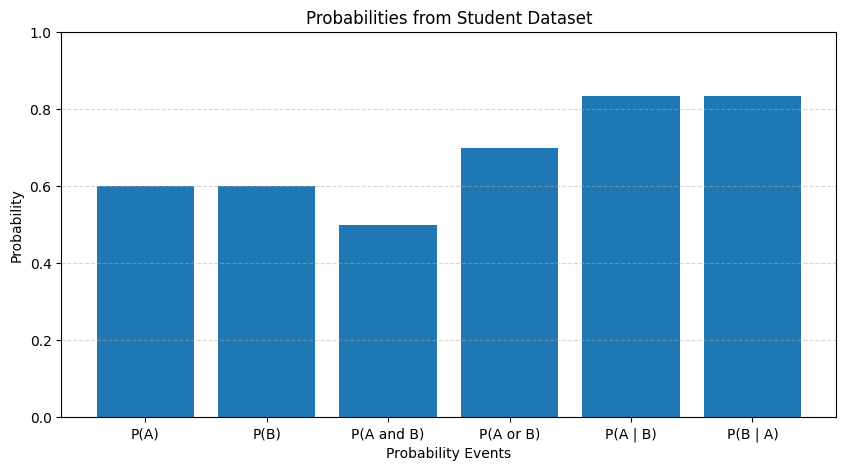

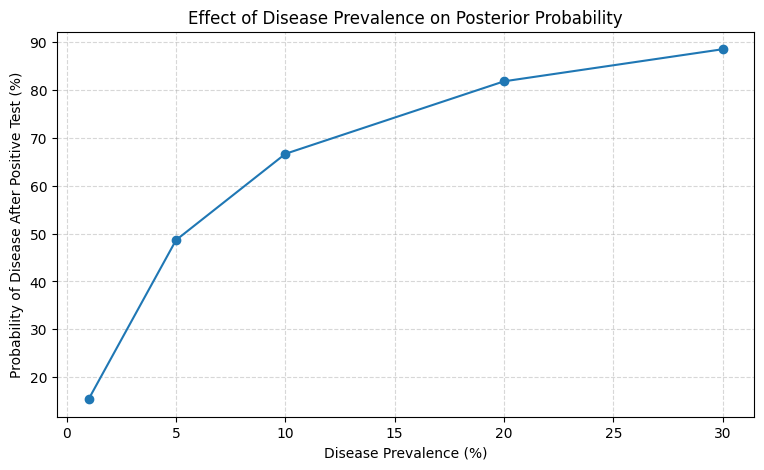

Prevalence vs Posterior Probability:
Prevalence: 1% -> Posterior probability: 15.38%
Prevalence: 5% -> Posterior probability: 48.65%
Prevalence: 10% -> Posterior probability: 66.67%
Prevalence: 20% -> Posterior probability: 81.82%
Prevalence: 30% -> Posterior probability: 88.52%


In [ ]:

# Exercise 6: Visualization

# Graph 1: Probabilities from the student dataset

probability_names = [
    "P(A)", "P(B)", "P(A and B)",
    "P(A or B)", "P(A | B)", "P(B | A)"
]

probability_values = [
    P_A, P_B, P_A_and_B,
    P_A_or_B, P_A_given_B, P_B_given_A
]

plt.figure(figsize=(10, 5))
plt.bar(probability_names, probability_values)
plt.title("Probabilities from Student Dataset")
plt.xlabel("Probability Events")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


# Graph 2: Effect of changing disease prevalence

prevalence_values = [0.01, 0.05, 0.10, 0.20, 0.30]
posterior_values = []

for prevalence in prevalence_values:
    no_disease = 1 - prevalence

    positive_probability = (
        P_positive_given_D * prevalence
        + P_positive_given_no_D * no_disease
    )

    posterior = (
        P_positive_given_D * prevalence
    ) / positive_probability

    posterior_values.append(posterior * 100)

plt.figure(figsize=(9, 5))
plt.plot(
    [p * 100 for p in prevalence_values],
    posterior_values,
    marker="o"
)

plt.title("Effect of Disease Prevalence on Posterior Probability")
plt.xlabel("Disease Prevalence (%)")
plt.ylabel("Probability of Disease After Positive Test (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print("Prevalence vs Posterior Probability:")
for prevalence, posterior in zip(prevalence_values, posterior_values):
    print(f"Prevalence: {prevalence * 100:.0f}% -> "
          f"Posterior probability: {posterior:.2f}%")
